# 최근접 이웃(K-Nearest Neighbor)

* 특별한 학습 모델 없이 가장 가까운 데이터 포인트를 기반으로 예측을 수행하는 방법
* 분류와 회귀 모두 지원


## K 최근접 이웃 분류

* 입력 데이터 포인트와 가장 가까운 k개의 훈련 데이터 포인트가 출력
* k개의 데이터 포인트 중 가장 많은 클래스가 예측 결과

### 붓꽃 데이터

In [1]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2) # 0.2, 0.3

In [2]:
X_train.shape, X_test.shape

((120, 4), (30, 4))

In [3]:
md = KNeighborsClassifier(n_neighbors=5) # 3, 5, 7
md.fit(X_train, y_train)

KNeighborsClassifier()

In [4]:
md.get_params()

{'algorithm': 'auto',
 'leaf_size': 30,
 'metric': 'minkowski',
 'metric_params': None,
 'n_jobs': None,
 'n_neighbors': 5,
 'p': 2,
 'weights': 'uniform'}

In [5]:
test_ex = np.array([[6, 3, 5, 1.6]])
pred = md.predict(test_ex)
iris = load_iris()
print(pred, iris['target_names'][pred])
md_pred = md.score(X_test, y_test)
print("KNN 테스트 데이터의 Score : {}".format(md_pred))

[2] ['virginica']
KNN 테스트 데이터의 Score : 0.9333333333333333


In [6]:
y_pred = md.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[14  0  0]
 [ 0  8  2]
 [ 0  0  6]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      0.80      0.89        10
           2       0.75      1.00      0.86         6

    accuracy                           0.93        30
   macro avg       0.92      0.93      0.92        30
weighted avg       0.95      0.93      0.93        30



# 다양한 분석 보조 도구들
- 모델 평가(Confusion Matrix, Classification Report)
- 데이터 정규화(Normalization)
- 교차 검증(Cross Validation)
- 최적 파라메터 찾기(Grid Search)
- 2차원 분류 이미지

In [7]:
import matplotlib.pyplot as plt

In [8]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.manifold import TSNE
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler     # 평균0, 분산1의 표준정규분포로 표준화
from sklearn.preprocessing import MinMaxScaler       # MinMaxScaler : 0 ~ 1사이로 정규화(or -1 ~ 1)

## 데이터 변환 - 정규화
- StandardScaler : 평균0, 분산1의 표준정규분포로 정규화(표준화)
- MinMaxScaler : 0 ~ 1 사이로 정규화(or -1 ~ 1)

In [15]:
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
print(X_test[:10,:])

[[5.1 3.5 1.4 0.2]
 [7.7 3.8 6.7 2.2]
 [4.7 3.2 1.6 0.2]
 [5.5 2.5 4.  1.3]
 [5.8 2.7 5.1 1.9]
 [4.8 3.  1.4 0.1]
 [6.3 2.5 5.  1.9]
 [7.7 2.6 6.9 2.3]
 [5.6 2.5 3.9 1.1]
 [6.7 3.3 5.7 2.1]]


In [10]:
md = KNeighborsClassifier()
md.fit(X_train, y_train)

KNeighborsClassifier()

In [11]:
print("KNN 학습 데이터 점수 : {}".format(md.score(X_train, y_train)))
print("KNN 테스트 데이터 점수 : {}".format(md.score(X_test, y_test)))

KNN 학습 데이터 점수 : 0.9833333333333333
KNN 테스트 데이터 점수 : 0.9666666666666667


In [21]:
scaler = StandardScaler()
# scaler = MinMaxScaler()

In [22]:
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)
print(X_test_scale[:10,:].round(3))

[[-0.895  1.033 -1.332 -1.326]
 [ 2.292  1.721  1.67   1.322]
 [-1.385  0.344 -1.218 -1.326]
 [-0.404 -1.262  0.141  0.13 ]
 [-0.037 -0.803  0.764  0.924]
 [-1.262 -0.115 -1.332 -1.458]
 [ 0.576 -1.262  0.707  0.924]
 [ 2.292 -1.033  1.783  1.454]
 [-0.282 -1.262  0.084 -0.135]
 [ 1.066  0.574  1.103  1.189]]


In [23]:
import pandas as pd
scaled_df = pd.DataFrame(data=X_train_scale)
scaled_df.describe()

,0,1,2,3
count,1.200000e+02,1.200000e+02,1.200000e+02,1.200000e+02
mean,1.036208e-15,4.144833e-16,3.404684e-16,3.053113e-16
std,1.004193e+00,1.004193e+00,1.004193e+00,1.004193e+00
min,-1.875126e+00,-2.409922e+00,-1.501612e+00,-1.458344e+00
25%,-8.946679e-01,-5.737911e-01,-1.275096e+00,-1.193592e+00
50%,-3.676717e-02,-1.147582e-01,3.671447e-01,1.301699e-01
75%,6.985763e-01,5.737911e-01,7.635477e-01,7.920507e-01
max,2.536935e+00,3.098472e+00,1.669612e+00,1.718684e+00


In [24]:
mdsc = KNeighborsClassifier()
mdsc.fit(X_train_scale, y_train)

KNeighborsClassifier()

In [25]:
print("KNN 표준화 학습 데이터 점수 : {}".format(mdsc.score(X_train_scale, y_train)))
print("KNN 표준화 테스트 데이터 점수 : {}".format(mdsc.score(X_test_scale, y_test)))

KNN 표준화 학습 데이터 점수 : 0.9583333333333334
KNN 표준화 테스트 데이터 점수 : 1.0


## 교차 검증(Cross Validation)

In [26]:
import os   # 또는 import multiprocessing

In [27]:
cross_validate(estimator = KNeighborsClassifier(),
               X=X, y=y, cv=5, # 3, 5, 10
               n_jobs=os.cpu_count(),  # same as -1 --> using all processors
               verbose=True)

[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   5 out of   5 | elapsed:    2.4s finished


{'fit_time': array([0.00231051, 0.00159931, 0.00411487, 0.00470853, 0.0015614 ]),
 'score_time': array([0.0043745 , 0.00299406, 0.00764775, 0.00997257, 0.00360942]),
 'test_score': array([0.96666667, 1.        , 0.93333333, 0.96666667, 1.        ])}

## 최적의 파라메터 설정 찾기 - GridSearch

In [28]:
param_grid = [{'n_neighbors' : [3, 5, 7],
               'weights': ['uniform', 'distance'],
               'algorithm': ['ball_tree', 'kd_tree', 'brute']}]

In [29]:
gs = GridSearchCV(estimator=KNeighborsClassifier(),
                  param_grid=param_grid,
                  n_jobs=-1,  # same as multiprocessing.cpu_count()
                  verbose=True)

In [30]:
gs.fit(X,y)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


GridSearchCV(estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid=[{'algorithm': ['ball_tree', 'kd_tree', 'brute'],
                          'n_neighbors': [3, 5, 7],
                          'weights': ['uniform', 'distance']}],
             verbose=True)

In [31]:
gs.best_params_

{'algorithm': 'ball_tree', 'n_neighbors': 7, 'weights': 'uniform'}

In [32]:
gs.best_estimator_

KNeighborsClassifier(algorithm='ball_tree', n_neighbors=7)

In [33]:
print("KNN 학습 GridSearch의 최적 점수 : {}".format(gs.best_score_))


KNN 학습 GridSearch의 최적 점수 : 0.9800000000000001


## 2차원 분류 분석 이미지

- meshgrid, contour, contourf : 2차원 영역 그리기
- t-SNE(t-distributed Stochastic Neighbor Embedding)
    - t-분포 기반 차원 축소 도구(그 외 PCA, UMAP)

In [34]:
def make_mg(x, y, h=0.1) :
    x_min, x_max = x.min()-1, x.max()+1
    y_min, y_max = y.min()-1, y.max()+1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                       np.arange(y_min, y_max, h))
    return xx, yy

def plot_cnts(clf, xx, yy, **params) :
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    out = plt.contourf(xx, yy, Z, **params)
    return out

In [35]:
tsne = TSNE(n_components=2)
Xc = tsne.fit_transform(X)

In [36]:
iris_2c_df = pd.DataFrame(data=Xc)
iris_2c_df['Target']=y
iris_2c_df

,0,1,Target
0,-24.284670,-0.196069,0
1,-21.731905,0.653882,0
2,-21.776773,-0.433848,0
3,-21.413086,-0.141203,0
4,-24.284908,-0.606254,0
...,...,...,...
145,14.369648,-2.493189,2
146,11.872075,-0.541414,2
147,13.772250,-1.774297,2
148,14.138768,-3.394210,2


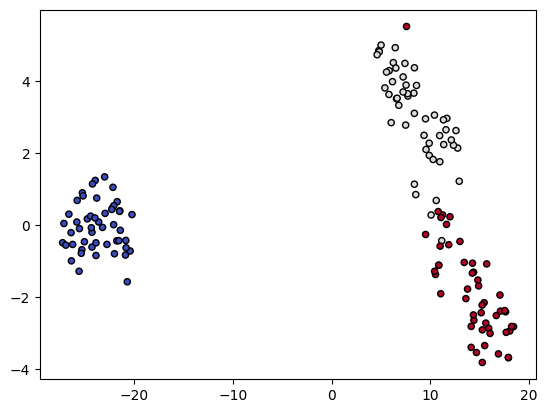

In [37]:
plt.scatter(Xc[:,0], Xc[:,1], c=y, cmap=plt.cm.coolwarm, s=20, edgecolors='k')

In [38]:
md = KNeighborsClassifier()
md.fit(Xc, y)
pred = md.predict(Xc)

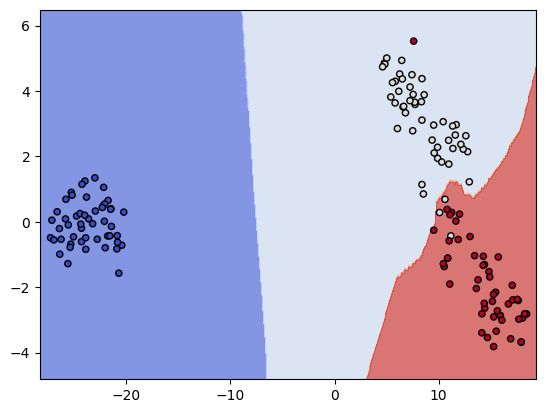

In [39]:
xx, yy = make_mg(Xc[:,0], Xc[:,1])
# plt.figure(figsize=(12,9))
plot_cnts(md, xx, yy, cmap=plt.cm.coolwarm, alpha=0.7)
plt.scatter(Xc[:,0], Xc[:,1], c=y, cmap=plt.cm.coolwarm, s=20, edgecolors='k')